Saved: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/inputs/waveform_aligned.npz
N = 1000000
dt = 0.1
FFT df = 1e-05 Hz
science t range = 0.0 99999.90000000001
tau range = -50000.0 49999.90000000001
raw peak time = -3.2741809263825417e-09
science peak index = 500000
science peak time = 50000.0


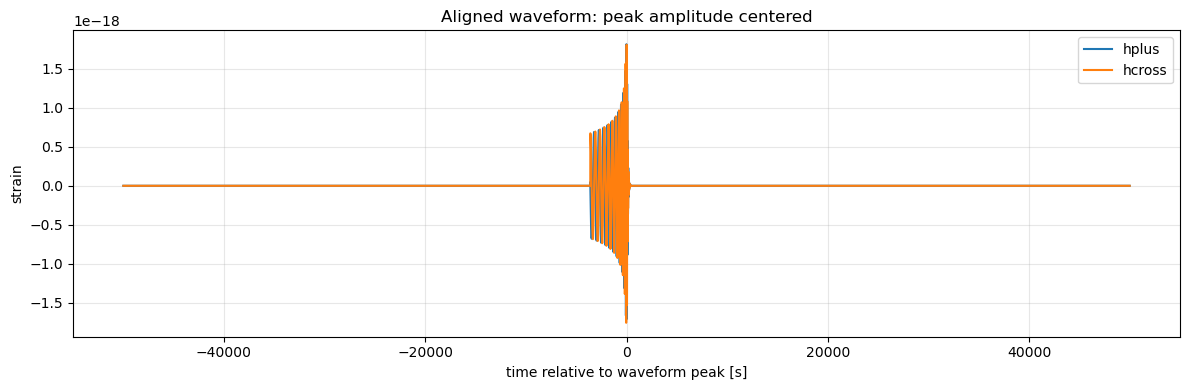

In [29]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

home = Path.cwd()

input = home / "inputs"
output = home / "outputs"
output.mkdir(exist_ok=True)

RAW_WAVEFORM = input / "my_waveform.npz"
ALIGNED_WAVEFORM = input / "waveform_aligned.npz"

# A 100000 s science segment gives an FFT frequency spacing of 1e-5 Hz
# at dt = 0.1 s, so the low-frequency cut is resolved by the saved record.
DATA_DURATION = 100_000.0
DT = 0.1

data = np.load(RAW_WAVEFORM)

t_raw = np.asarray(data["t"], dtype=float)
hp_raw = np.asarray(data["hplus"], dtype=float)
hc_raw = np.asarray(data["hcross"], dtype=float)

if not (len(t_raw) == len(hp_raw) == len(hc_raw)):
    raise ValueError("t, hplus, and hcross must have the same length.")

amp_raw = np.sqrt(hp_raw**2 + hc_raw**2)
peak_index_raw = int(np.argmax(amp_raw))
peak_time_raw = float(t_raw[peak_index_raw])

# Shift raw waveform so peak amplitude is at tau = 0.
t_peak_centered = t_raw - peak_time_raw

n = int(round(DATA_DURATION / DT))
t = np.arange(n, dtype=float) * DT

# The saved science time starts at zero. Tau is only the interpolation axis,
# placing the waveform peak in the middle of the science segment.
tau = t - DATA_DURATION / 2.0

hp = np.interp(tau, t_peak_centered, hp_raw, left=0.0, right=0.0)
hc = np.interp(tau, t_peak_centered, hc_raw, left=0.0, right=0.0)

np.savez(
    ALIGNED_WAVEFORM,
    t=t,
    hplus=hp,
    hcross=hc,
)

amp = np.sqrt(hp**2 + hc**2)
peak_index = int(np.argmax(amp))

print("Saved:", ALIGNED_WAVEFORM)
print("N =", n)
print("dt =", DT)
print("FFT df =", 1.0 / (n * DT), "Hz")
print("science t range =", t.min(), t.max())
print("tau range =", tau.min(), tau.max())
print("raw peak time =", peak_time_raw)
print("science peak index =", peak_index)
print("science peak time =", t[peak_index])

plt.figure(figsize=(12, 4))
plt.plot(tau, hp, label="hplus")
plt.plot(tau, hc, label="hcross")
plt.xlabel("time relative to waveform peak [s]")
plt.ylabel("strain")
plt.title("Aligned waveform: peak amplitude centered")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output / "01_aligned_waveform_peak_centered.png", dpi=150)
plt.show()


You are using an orbit file in a version that might not be fully supported


Loaded peak-centered waveform:
  waveform N = 1000000
  burn-in N  = 6001
  total N    = 1006001
  dt        = 0.09999999999854481 s
  t range   = [0.0, 99999.90000000001]
  peak idx  = 500000
  hp range  = [-1.708e-18, 1.814e-18]
  hc range  = [-1.756e-18, 1.808e-18]

Orbit mapping:
  orbit range     = [61171239.327664, 61671639.327664]
  orbit dt        = 600.0 s
  orbit size      = 835
  required span   = 100599.99999853608 s
  orbit span      = 500400.0 s
  orbit start used= 61371139.32766473
  t_lisa range    = [61371139.32766473, 61471739.32766327]
  waveform starts = 61371739.42766473
  t_lisa at peak  = 61421739.427664

Computing LISA GW response...


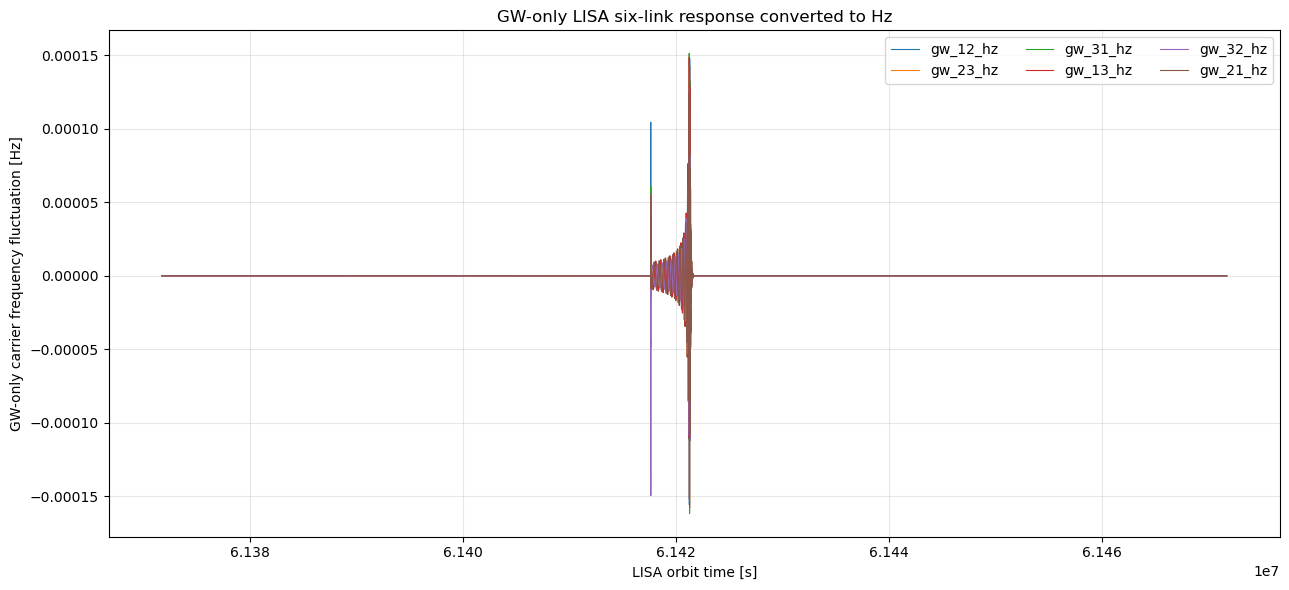

You are using an orbit file in a version that might not be fully supported



Saved GW-only links: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/six_links_gw_only.csv
Saved GW response HDF5 for lisainstrument: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/gws.h5
Note: gws.h5 stores dimensionless fractional-frequency response; lisainstrument multiplies by central_freq internally.


In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

from lisagwresponse import ReadStrain

WAVEFORM_FILE = input / "waveform_aligned.npz"
ORBITS_FILE = input / "orbits.h5"

GW_FILE = output / "gws.h5"
GW_ONLY_CSV = output / "six_links_gw_only.csv"
PLOT_FILE = output / "02_gw_only_six_links_peak_centered.png"


# ============================================================
# Settings
# ============================================================

RA = np.pi / 4
DEC = 0.3

LINKS = [12, 23, 31, 13, 32, 21]
LINK_LABELS = ["12", "23", "31", "13", "32", "21"]

ORBIT_START_OFFSET_SECONDS = None
BURN_IN_SECONDS = 600.0
CENTRAL_FREQ_HZ = 2.816e14


# ============================================================
# Helpers
# ============================================================

def read_orbit_time_range(orbits_file):
    with h5py.File(orbits_file, "r") as f:
        attrs = dict(f.attrs)
        t0 = float(attrs["t0"])
        dt = float(attrs["dt"])
        size = int(attrs["size"])
        t1 = t0 + dt * (size - 1)
    return t0, t1, dt, size


# ============================================================
# Main
# ============================================================

data = np.load(WAVEFORM_FILE)

t_data = np.asarray(data["t"], dtype=float)
hplus = np.asarray(data["hplus"], dtype=float)
hcross = np.asarray(data["hcross"], dtype=float)

dt = float(np.median(np.diff(t_data)))
n_waveform = len(t_data)
burn_in_size = int(np.ceil(BURN_IN_SECONDS / dt))
n_total = burn_in_size + n_waveform

print("Loaded peak-centered waveform:")
print(f"  waveform N = {n_waveform}")
print(f"  burn-in N  = {burn_in_size}")
print(f"  total N    = {n_total}")
print(f"  dt        = {dt} s")
print(f"  t range   = [{t_data.min()}, {t_data.max()}]")
print(f"  peak idx  = {np.argmax(np.sqrt(hplus**2 + hcross**2))}")
print(f"  hp range  = [{hplus.min():.3e}, {hplus.max():.3e}]")
print(f"  hc range  = [{hcross.min():.3e}, {hcross.max():.3e}]")

orbit_t0, orbit_t1, orbit_dt, orbit_size = read_orbit_time_range(ORBITS_FILE)

required_span = dt * (n_total - 1)
orbit_span = orbit_t1 - orbit_t0
if required_span > orbit_span:
    raise ValueError(
        "Burn-in plus waveform duration is longer than the generated orbit file. "
        f"Need {required_span} s, orbit has {orbit_span} s."
    )

if ORBIT_START_OFFSET_SECONDS is None:
    orbit_start_lisa = orbit_t0 + 0.5 * (orbit_span - required_span)
else:
    orbit_start_lisa = orbit_t0 + ORBIT_START_OFFSET_SECONDS

t_waveform_full = (np.arange(n_total, dtype=float) - burn_in_size) * dt
t_lisa = orbit_start_lisa + np.arange(n_total, dtype=float) * dt
science = np.arange(n_total) >= burn_in_size
hplus_full = np.zeros(n_total, dtype=float)
hcross_full = np.zeros(n_total, dtype=float)
hplus_full[science] = hplus
hcross_full[science] = hcross

print("\nOrbit mapping:")
print(f"  orbit range     = [{orbit_t0}, {orbit_t1}]")
print(f"  orbit dt        = {orbit_dt} s")
print(f"  orbit size      = {orbit_size}")
print(f"  required span   = {required_span} s")
print(f"  orbit span      = {orbit_span} s")
print(f"  orbit start used= {orbit_start_lisa}")
print(f"  t_lisa range    = [{t_lisa.min()}, {t_lisa.max()}]")
peak_idx_waveform = int(np.argmax(np.sqrt(hplus**2 + hcross**2)))
peak_idx_full = burn_in_size + peak_idx_waveform
print(f"  waveform starts = {t_lisa[burn_in_size]}")
print(f"  t_lisa at peak  = {t_lisa[peak_idx_full]}")

if t_lisa.min() < orbit_t0 or t_lisa.max() > orbit_t1:
    raise ValueError("Burn-in plus waveform time grid lies outside orbit file time range.")

print("\nComputing LISA GW response...")

source = ReadStrain(
    t_lisa,
    hplus_full,
    hcross_full,
    orbits=str(ORBITS_FILE),
    ra=RA,
    dec=DEC,
)

y_gw = source.compute_gw_response(t_lisa, LINKS)
y_gw_hz = CENTRAL_FREQ_HZ * y_gw

# y_gw is dimensionless fractional-frequency response. Keep it in this unit
# for gws.h5 because lisainstrument applies central_freq internally. The
# *_hz columns are for direct plotting/comparison with lisainstrument outputs.
df = pd.DataFrame(
    np.column_stack([np.arange(n_total), t_waveform_full, t_lisa, science.astype(int), y_gw, y_gw_hz]),
    columns=[
        "sample",
        "t_waveform",
        "t_lisa",
        "is_science",
        "gw_12",
        "gw_23",
        "gw_31",
        "gw_13",
        "gw_32",
        "gw_21",
        "gw_12_hz",
        "gw_23_hz",
        "gw_31_hz",
        "gw_13_hz",
        "gw_32_hz",
        "gw_21_hz",
    ],
)

# Plot GW-only response in the same Hz unit as lisainstrument carrier fluctuations.
plt.figure(figsize=(13, 6))
for lab in LINK_LABELS:
    plt.plot(t_lisa[science], df.loc[science, f"gw_{lab}_hz"], lw=0.8, label=f"gw_{lab}_hz")
plt.xlabel("LISA orbit time [s]")
plt.ylabel("GW-only carrier frequency fluctuation [Hz]")
plt.title("GW-only LISA six-link response converted to Hz")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150)
plt.show()


df.to_csv(GW_ONLY_CSV, index=False)
print(f"\nSaved GW-only links: {GW_ONLY_CSV}")

if GW_FILE.exists():
    GW_FILE.unlink()

source.write(
    str(GW_FILE),
    t0=float(t_lisa[0]),
    dt=dt,
    size=n_total,
)

print(f"Saved GW response HDF5 for lisainstrument: {GW_FILE}")
print("Note: gws.h5 stores dimensionless fractional-frequency response; lisainstrument multiplies by central_freq internally.")

#plt.figure(figsize=(13, 6))

#for lab in LINK_LABELS:
#    plt.plot(t_lisa, df[f"gw_{lab}"], lw=0.8, label=f"gw_{lab}")

#plt.axvline(0.0, color="k", ls="--", alpha=0.7, label="waveform peak")
#plt.xlabel("time relative to waveform peak [s]")
#plt.ylabel("GW-only LISA link response")
#plt.title("GW-only LISA six-link response, waveform peak centered")
#plt.grid(alpha=0.3)
#plt.legend(ncol=3)
#plt.tight_layout()
#plt.savefig(PLOT_FILE, dpi=150)
#plt.show()

#print(f"Saved plot: {PLOT_FILE}")


Loaded GW timing:
  total N  = 1006001
  science N= 1000000
  burn-in N= 6001
  dt       = 0.10000000149011612 s
  waveform t range = [-600.0999999912674, 99999.8999985448]
  t_lisa range     = [61371139.32766473, 61471739.32766327]
  t0_lisa  = 61371139.32766473

Running LISA Instrument...
  central_freq = 2.816000e+14 Hz


Using default set of locking beatnote frequencies might cause interferometric beatnote frequencies to fall outside the requirement range of 5..25 MHz


Saved instrument output: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/lisa_instrument_output.h5
Saved noisy six-link CSV: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/six_links_noisy.csv
   sample  instrument_sample  t_waveform        t_lisa   noisy_12   noisy_23  \
0       0               6001         0.0  6.137174e+07 -49.181321  38.593437   
1       1               6002         0.1  6.137174e+07 -32.899446 -17.168379   
2       2               6003         0.2  6.137174e+07  17.950170 -79.724660   
3       3               6004         0.3  6.137174e+07  44.940672 -74.560537   
4       4               6005         0.4  6.137174e+07  27.568228   4.098520   

       noisy_31   noisy_13   noisy_32      noisy_21  
0 -2.703077e-15 -18.516228  33.373473 -1.792635e-15  
1 -4.132496e-16 -25.877965 -16.421838 -1.983068e-15  
2  2.196638e-15  -4.280309 -76.912116 -1.844554e-15  
3  2.894658e-15  18.346239 -77.890525 -8.262207e-16  
4  1.754294e-15  1

/var/folders/p_/x076xwcj62g0046rqqx8v56h0000gn/T/ipykernel_6274/711894460.py:159: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/var/folders/p_/x076xwcj62g0046rqqx8v56h0000gn/T/ipykernel_6274/711894460.py:160: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(PLOT_FILE, dpi=150)
/opt/miniconda3/envs/lisa-tf/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


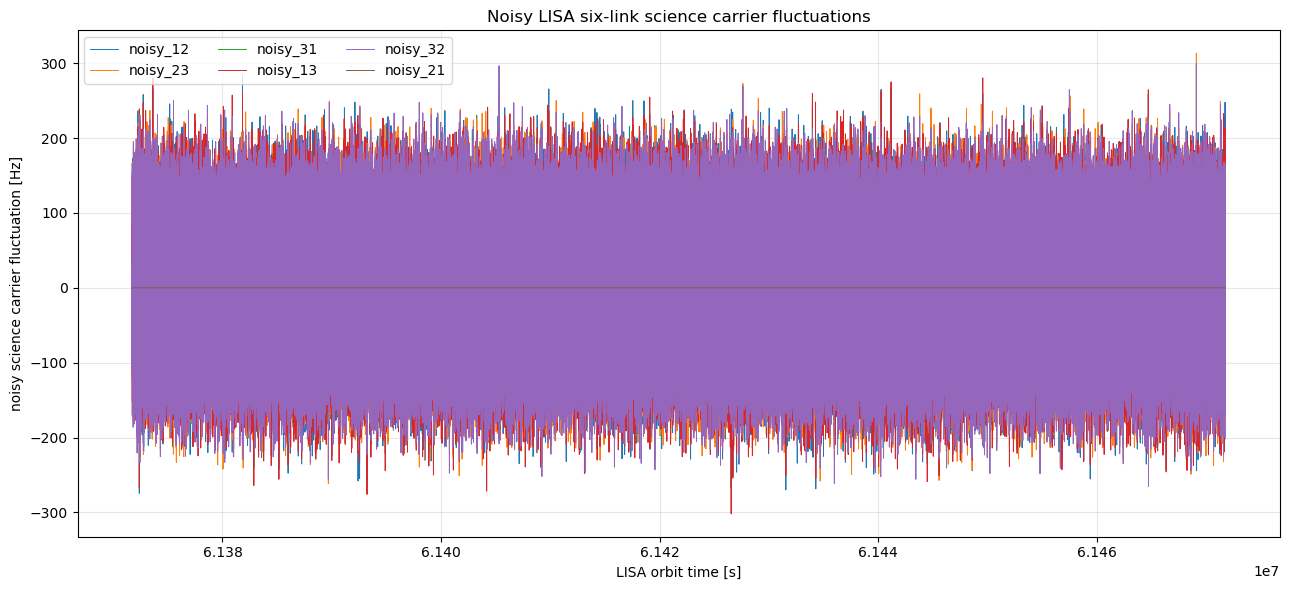

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/03_noisy_six_links.png


In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

from lisainstrument import Instrument


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"
GW_FILE = OUTPUT_DIR / "gws.h5"

INPUT_DIR = BASE_DIR / "inputs"
ORBITS_FILE = INPUT_DIR / "orbits.h5"

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"
NOISY_CSV = OUTPUT_DIR / "six_links_noisy.csv"
PLOT_FILE = OUTPUT_DIR / "03_noisy_six_links.png"


# ============================================================
# Settings
# ============================================================

LINK_LABELS = ["12", "23", "31", "13", "32", "21"]
SEED = 12345
CENTRAL_FREQ_HZ = 2.816e14


# ============================================================
# Load timing metadata from GW-only response
# ============================================================

gw = pd.read_csv(GW_ONLY_CSV, usecols=["t_waveform", "t_lisa", "is_science"])

t_waveform = gw["t_waveform"].to_numpy()
t_lisa = gw["t_lisa"].to_numpy()
if "is_science" in gw.columns:
    is_science = gw["is_science"].astype(bool).to_numpy()
else:
    is_science = np.ones(len(gw), dtype=bool)
burn_in_size = int(np.argmax(is_science)) if not is_science[0] else 0

dt = float(np.median(np.diff(t_lisa)))
n_total = len(t_lisa)
n_science = int(np.sum(is_science))
t0_lisa = float(t_lisa[0])

print("Loaded GW timing:")
print(f"  total N  = {n_total}")
print(f"  science N= {n_science}")
print(f"  burn-in N= {burn_in_size}")
print(f"  dt       = {dt} s")
print(f"  waveform t range = [{t_waveform.min()}, {t_waveform.max()}]")
print(f"  t_lisa range     = [{t_lisa.min()}, {t_lisa.max()}]")
print(f"  t0_lisa  = {t0_lisa}")


# ============================================================
# Run LISA Instrument
# ============================================================

print("\nRunning LISA Instrument...")
print(f"  central_freq = {CENTRAL_FREQ_HZ:.6e} Hz")

if INSTRUMENT_FILE.exists():
    INSTRUMENT_FILE.unlink()

instrument = Instrument(
    size=n_total,
    dt=dt,
    t0=t0_lisa,
    orbits=str(ORBITS_FILE),
    gws=str(GW_FILE),
    central_freq=CENTRAL_FREQ_HZ,
    seed=SEED,
)

if hasattr(instrument, "export_hdf5"):
    instrument.export_hdf5(
        path=str(INSTRUMENT_FILE),
        overwrite=True,
    )
elif hasattr(instrument, "write"):
    instrument.write(
        str(INSTRUMENT_FILE),
        overwrite=True,
    )
else:
    instrument.simulate()
    raise RuntimeError("Could not find export_hdf5() or write().")

print(f"Saved instrument output: {INSTRUMENT_FILE}")


# ============================================================
# Extract noisy science carrier fluctuations
# ============================================================

GROUP = "debug/sci_carrier_fluctuations"

with h5py.File(INSTRUMENT_FILE, "r") as f:
    arrays = []

    for lab in LINK_LABELS:
        path = f"{GROUP}/{lab}"

        if path not in f:
            raise KeyError(
                f"Missing dataset {path}. "
                "Print HDF5 tree and check dataset names."
            )

        arrays.append(np.asarray(f[path]))

m_total = min(len(a) for a in arrays)
m_total = min(m_total, n_total)
science_idx = np.flatnonzero(is_science[:m_total])

df = pd.DataFrame({
    "sample": np.arange(len(science_idx)),
    "instrument_sample": science_idx,
    "t_waveform": t_waveform[science_idx],
    "t_lisa": t_lisa[science_idx],
})

for lab, arr in zip(LINK_LABELS, arrays):
    df[f"noisy_{lab}"] = arr[science_idx]

df.to_csv(NOISY_CSV, index=False)

print(f"Saved noisy six-link CSV: {NOISY_CSV}")
print(df.head())


# ============================================================
# Plot noisy links
# ============================================================

plt.figure(figsize=(13, 6))

for lab in LINK_LABELS:
    plt.plot(df["t_lisa"], df[f"noisy_{lab}"], lw=0.7, label=f"noisy_{lab}")

plt.xlabel("LISA orbit time [s]")
plt.ylabel("noisy science carrier fluctuation [Hz]")
plt.title("Noisy LISA six-link science carrier fluctuations")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150)
plt.show()

print(f"Saved plot: {PLOT_FILE}")


You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')


Loading instrument output with PyTDI...
Loaded PyTDI Data:
  fs      = 9.99999985098839 Hz
  burn-in skipped = 6001
  extra skipped   = 0
  TDI load skipped = 0
  science crop start = 6001
  dt for FFT cuts = 0.09999999999854481 s
Using delay derivatives.

Building Michelson X2, Y2, Z2...
Evaluating TDI...
  frequency cut = [1e-05, 0.01] Hz

Orbit-time TDI timing:
  n             = 1000000
  t_lisa min    = 61371739.428 s
  t_lisa max    = 61471739.328 s
  start index   = 6001

TDI diagnostics:
  X2: min=-2.588e-04, max=2.349e-04, std=9.195e-06
  Y2: min=-2.448e-04, max=2.423e-04, std=9.025e-06
  Z2: min=-2.303e-04, max=2.516e-04, std=9.054e-06
  A2: min=-2.811e-04, max=3.176e-04, std=1.129e-05
  E2: min=-2.944e-04, max=2.978e-04, std=1.097e-05
  T2: min=-4.263e-06, max=3.839e-06, std=4.265e-07

Saved TDI CSV: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/tdi_michelson_XYZ_AET.csv


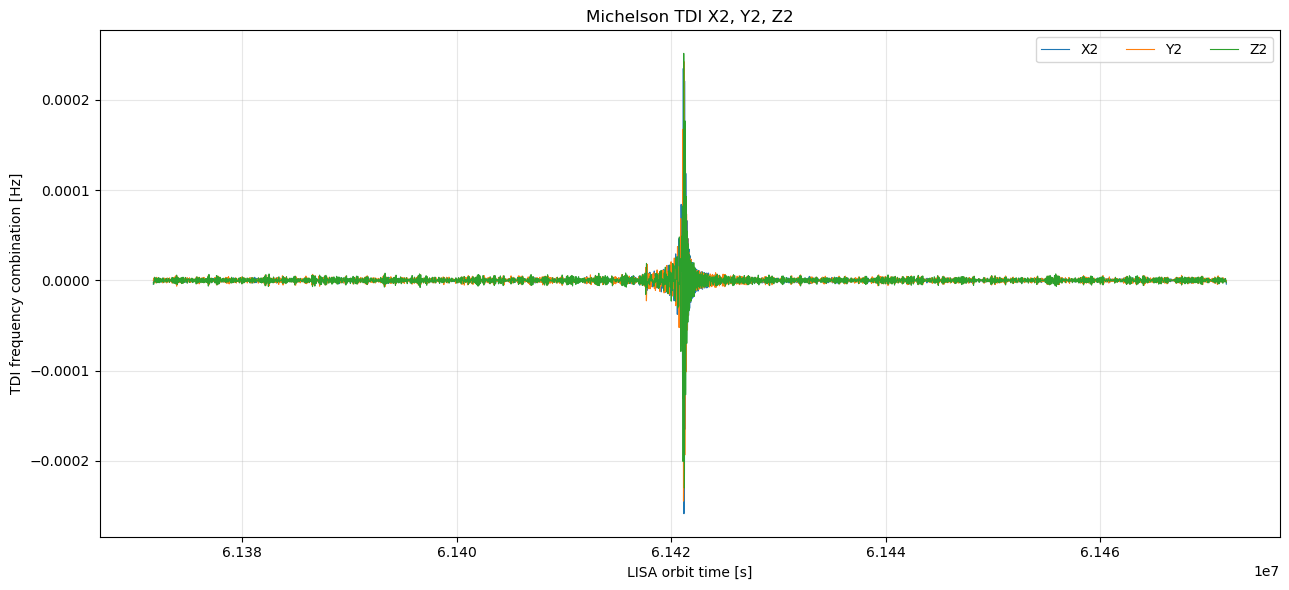

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/04_tdi_XYZ_orbit_time.png


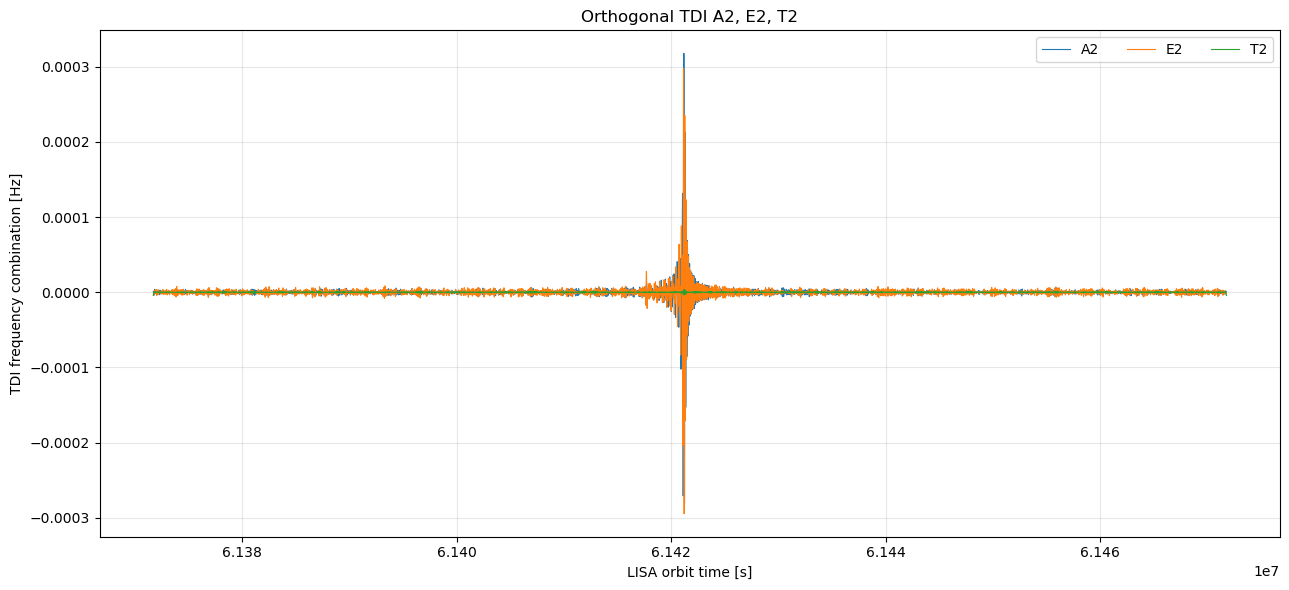

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/04_tdi_AET_orbit_time.png


In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytdi import Data
import pytdi.michelson


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"
GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"

TDI_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
PLOT_XYZ = PLOT_DIR / "04_tdi_XYZ_orbit_time.png"
PLOT_AET = PLOT_DIR / "04_tdi_AET_orbit_time.png"


# ============================================================
# Settings
# ============================================================

EXTRA_SKIPPED = 0
EDGE_CROP = 0
UNIT = "frequency"
INTERP_ORDER = 31
GENERATION = 2
FREQ_LOW_HZ = 1e-5
FREQ_HIGH_HZ = 1e-2


# ============================================================
# Helpers
# ============================================================

def get_delay_derivatives_if_available(data):
    if hasattr(data, "delay_derivatives"):
        return data.delay_derivatives
    if hasattr(data, "delay_derivs"):
        return data.delay_derivs
    if hasattr(data, "derivatives"):
        return data.derivatives
    return None


def crop(arr, edge):
    if edge <= 0:
        return arr

    if len(arr) <= 2 * edge:
        print(f"Array too short for EDGE_CROP={edge}; not cropping.")
        return arr

    return arr[edge:-edge]



def apply_frequency_cut(arr, dt, low_hz, high_hz):
    freqs = np.fft.rfftfreq(len(arr), d=dt)
    spectrum = np.fft.rfft(arr)
    keep = (freqs >= low_hz) & (freqs <= high_hz)
    spectrum[~keep] = 0.0
    return np.fft.irfft(spectrum, n=len(arr))

def plot_channels(x, channels, title, ylabel, outfile):
    plt.figure(figsize=(13, 6))

    for name, y in channels.items():
        plt.plot(x, y, lw=0.8, label=name)

    plt.xlabel("LISA orbit time [s]")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(ncol=3)
    plt.tight_layout()
    plt.savefig(outfile, dpi=150)
    plt.show()

    print(f"Saved plot: {outfile}")


# ============================================================
# Main
# ============================================================

def main():
    gw_meta = pd.read_csv(GW_ONLY_CSV)

    if "t_lisa" not in gw_meta.columns:
        raise ValueError("Expected column t_lisa in six_links_gw_only.csv")

    t_lisa_meta = gw_meta["t_lisa"].to_numpy()
    if "t_waveform" in gw_meta.columns:
        t_sampling_meta = gw_meta["t_waveform"].to_numpy()
    else:
        t_sampling_meta = t_lisa_meta
    if "is_science" in gw_meta.columns:
        is_science = gw_meta["is_science"].astype(bool).to_numpy()
    else:
        is_science = np.ones(len(gw_meta), dtype=bool)
    burn_in_size = int(np.argmax(is_science)) if not is_science[0] else 0
    skipped = burn_in_size + EXTRA_SKIPPED
    dt_tdi = float(np.median(np.diff(t_sampling_meta)))

    print("Loading instrument output with PyTDI...")

    data = Data.from_instrument(
        str(INSTRUMENT_FILE),
        signals="fluctuations",
        skipped=0,
    )

    print("Loaded PyTDI Data:")
    print(f"  fs      = {data.fs} Hz")
    print(f"  burn-in skipped = {burn_in_size}")
    print(f"  extra skipped   = {EXTRA_SKIPPED}")
    print(f"  TDI load skipped = 0")
    print(f"  science crop start = {skipped}")
    print(f"  dt for FFT cuts = {dt_tdi} s")

    delay_derivatives = get_delay_derivatives_if_available(data)

    if delay_derivatives is None:
        print("Warning: no delay derivatives found.")
    else:
        print("Using delay derivatives.")

    if GENERATION == 2:
        X_comb = pytdi.michelson.X2
        Y_comb = pytdi.michelson.Y2
        Z_comb = pytdi.michelson.Z2
        suffix = "2"
    else:
        X_comb = pytdi.michelson.X1
        Y_comb = pytdi.michelson.Y1
        Z_comb = pytdi.michelson.Z1
        suffix = "1"

    build_kwargs = {"order": INTERP_ORDER}

    if delay_derivatives is not None:
        build_kwargs["delay_derivatives"] = delay_derivatives

    print(f"\nBuilding Michelson X{suffix}, Y{suffix}, Z{suffix}...")

    X_built = X_comb.build(data.delays, data.fs, **build_kwargs)
    Y_built = Y_comb.build(data.delays, data.fs, **build_kwargs)
    Z_built = Z_comb.build(data.delays, data.fs, **build_kwargs)

    print("Evaluating TDI...")

    X = X_built(data.measurements, unit=UNIT)
    Y = Y_built(data.measurements, unit=UNIT)
    Z = Z_built(data.measurements, unit=UNIT)

    A = (Z - X) / np.sqrt(2.0)
    E = (X - 2.0 * Y + Z) / np.sqrt(6.0)
    T = (X + Y + Z) / np.sqrt(3.0)

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))

    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]

    # Crop after TDI evaluation so delay/interpolation operators can use the burn-in samples.
    start = skipped + EDGE_CROP
    stop = min(n, len(t_lisa_meta)) - EDGE_CROP
    if stop <= start:
        raise ValueError("Not enough samples after burn-in and edge crop.")

    X = X[start:stop]
    Y = Y[start:stop]
    Z = Z[start:stop]
    A = A[start:stop]
    E = E[start:stop]
    T = T[start:stop]
    t_lisa = t_lisa_meta[start:stop]

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T), len(t_lisa))
    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]
    t_lisa = t_lisa[:n]

    X = apply_frequency_cut(X, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
    Y = apply_frequency_cut(Y, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
    Z = apply_frequency_cut(Z, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
    A = apply_frequency_cut(A, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
    E = apply_frequency_cut(E, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
    T = apply_frequency_cut(T, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)

    print(f"  frequency cut = [{FREQ_LOW_HZ}, {FREQ_HIGH_HZ}] Hz")
    sample = np.arange(n)

    print("\nOrbit-time TDI timing:")
    print(f"  n             = {n}")
    print(f"  t_lisa min    = {t_lisa.min():.3f} s")
    print(f"  t_lisa max    = {t_lisa.max():.3f} s")
    print(f"  start index   = {start}")

    print("\nTDI diagnostics:")
    for name, arr in {
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    }.items():
        print(
            f"  {name}: "
            f"min={np.min(arr):.3e}, "
            f"max={np.max(arr):.3e}, "
            f"std={np.std(arr):.3e}"
        )

    df = pd.DataFrame({
        "sample": sample,
        "instrument_sample": sample + start,
        "t_lisa": t_lisa,
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    })

    df.to_csv(TDI_CSV, index=False)
    print(f"\nSaved TDI CSV: {TDI_CSV}")

    plot_channels(
        t_lisa,
        {f"X{suffix}": X, f"Y{suffix}": Y, f"Z{suffix}": Z},
        f"Michelson TDI X{suffix}, Y{suffix}, Z{suffix}",
        "TDI frequency combination [Hz]",
        PLOT_XYZ,
    )

    plot_channels(
        t_lisa,
        {f"A{suffix}": A, f"E{suffix}": E, f"T{suffix}": T},
        f"Orthogonal TDI A{suffix}, E{suffix}, T{suffix}",
        "TDI frequency combination [Hz]",
        PLOT_AET,
    )


if __name__ == "__main__":
    main()


You are using a GW file in a version that might not be fully supported
You are using an orbit file in a version that might not be fully supported


Loading GW-only response with PyTDI...
Loaded GW-only PyTDI Data:
  fs       = 10.00000000014552 Hz
  burn-in skipped = 6001
  extra skipped   = 0
  TDI load skipped = 0
  science crop start = 6001
  dt for FFT cuts = 0.09999999999854481 s
  central_freq for Hz conversion = 2.816000e+14 Hz

Building GW-only Michelson X2, Y2, Z2...
Evaluating GW-only TDI...
  frequency cut = [1e-05, 0.01] Hz
  converted GW-only TDI from fractional-frequency to Hz

GW-only TDI timing:
  n          = 1000000
  t_lisa min = 61371739.428 s
  t_lisa max = 61471739.328 s

GW-only TDI diagnostics:
  X2_gw_hz: min=-2.601e-04, max=2.353e-04, std=9.196e-06
  Y2_gw_hz: min=-2.426e-04, max=2.421e-04, std=8.842e-06
  Z2_gw_hz: min=-2.297e-04, max=2.503e-04, std=8.836e-06
  A2_gw_hz: min=-2.818e-04, max=3.176e-04, std=1.118e-05
  E2_gw_hz: min=-2.947e-04, max=2.955e-04, std=1.076e-05
  T2_gw_hz: min=-2.906e-06, max=3.312e-06, std=1.163e-07

Saved GW-only TDI CSV: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link

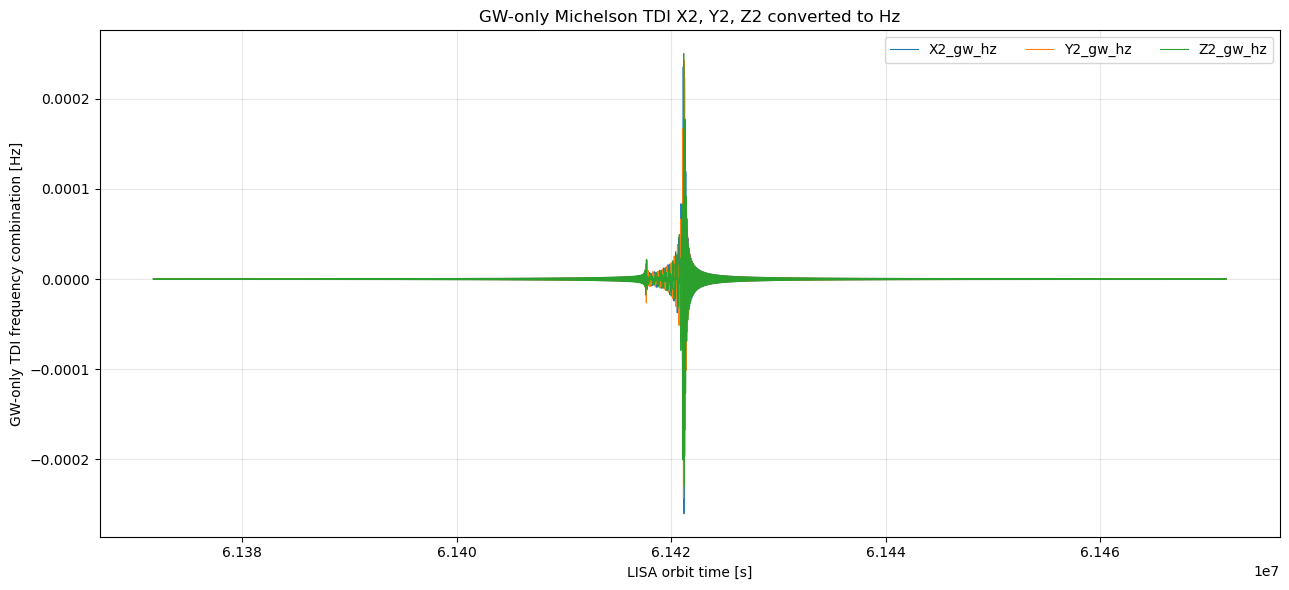

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/05_tdi_gw_only_XYZ.png


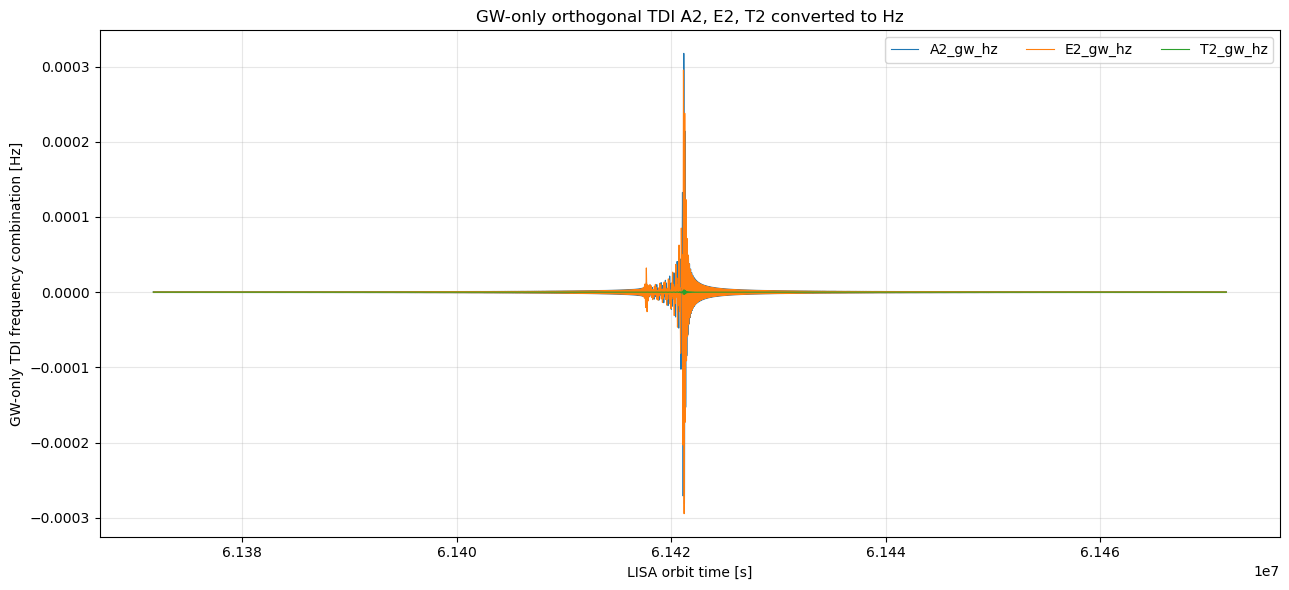

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/05_tdi_gw_only_AET.png


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytdi import Data
import pytdi.michelson


# ============================================================
# GW-only TDI from six LISA GW response links
# ============================================================

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

GW_FILE = OUTPUT_DIR / "gws.h5"
GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"
ORBITS_FILE = BASE_DIR / "inputs" / "orbits.h5"

TDI_GW_ONLY_CSV = OUTPUT_DIR / "tdi_gw_only_XYZ_AET.csv"
PLOT_GW_ONLY_XYZ = PLOT_DIR / "05_tdi_gw_only_XYZ.png"
PLOT_GW_ONLY_AET = PLOT_DIR / "05_tdi_gw_only_AET.png"

EXTRA_SKIPPED = 0
EDGE_CROP = 0
UNIT = "frequency"
INTERP_ORDER = 31
GENERATION = 2
FREQ_LOW_HZ = 1e-5
FREQ_HIGH_HZ = 1e-2
GW_DATASET = "tps"
ORBIT_DATASET = "tps/ppr"
CENTRAL_FREQ_HZ = 2.816e14


def crop(arr, edge):
    if edge <= 0:
        return arr
    if len(arr) <= 2 * edge:
        print(f"Array too short for EDGE_CROP={edge}; not cropping.")
        return arr
    return arr[edge:-edge]



def apply_frequency_cut(arr, dt, low_hz, high_hz):
    freqs = np.fft.rfftfreq(len(arr), d=dt)
    spectrum = np.fft.rfft(arr)
    keep = (freqs >= low_hz) & (freqs <= high_hz)
    spectrum[~keep] = 0.0
    return np.fft.irfft(spectrum, n=len(arr))

def get_delay_derivatives_if_available(data):
    if hasattr(data, "delay_derivatives"):
        return data.delay_derivatives
    if hasattr(data, "delay_derivs"):
        return data.delay_derivs
    if hasattr(data, "derivatives"):
        return data.derivatives
    return None


def plot_channels(x, channels, title, ylabel, outfile):
    plt.figure(figsize=(13, 6))
    for name, y in channels.items():
        plt.plot(x, y, lw=0.8, label=name)
    plt.xlabel("LISA orbit time [s]")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(ncol=3)
    plt.tight_layout()
    plt.savefig(outfile, dpi=150)
    plt.show()
    print(f"Saved plot: {outfile}")


# Load the original orbit-time grid used to write gws.h5.
gw_meta = pd.read_csv(GW_ONLY_CSV)
if "t_lisa" not in gw_meta.columns:
    raise ValueError("Expected column t_lisa in six_links_gw_only.csv")

t_lisa_meta = gw_meta["t_lisa"].to_numpy()
if "t_waveform" in gw_meta.columns:
    t_sampling_meta = gw_meta["t_waveform"].to_numpy()
else:
    t_sampling_meta = t_lisa_meta
if "is_science" in gw_meta.columns:
    is_science = gw_meta["is_science"].astype(bool).to_numpy()
else:
    is_science = np.ones(len(gw_meta), dtype=bool)
burn_in_size = int(np.argmax(is_science)) if not is_science[0] else 0
skipped = burn_in_size + EXTRA_SKIPPED
dt_tdi = float(np.median(np.diff(t_sampling_meta)))

print("Loading GW-only response with PyTDI...")
data = Data.from_gws(
    str(GW_FILE),
    str(ORBITS_FILE),
    skipped=0,
    gw_dataset=GW_DATASET,
    orbit_dataset=ORBIT_DATASET,
)

print("Loaded GW-only PyTDI Data:")
print(f"  fs       = {data.fs} Hz")
print(f"  burn-in skipped = {burn_in_size}")
print(f"  extra skipped   = {EXTRA_SKIPPED}")
print(f"  TDI load skipped = 0")
print(f"  science crop start = {skipped}")
print(f"  dt for FFT cuts = {dt_tdi} s")
print(f"  central_freq for Hz conversion = {CENTRAL_FREQ_HZ:.6e} Hz")

if GENERATION == 2:
    X_comb = pytdi.michelson.X2
    Y_comb = pytdi.michelson.Y2
    Z_comb = pytdi.michelson.Z2
    suffix = "2"
else:
    X_comb = pytdi.michelson.X1
    Y_comb = pytdi.michelson.Y1
    Z_comb = pytdi.michelson.Z1
    suffix = "1"

build_kwargs = {"order": INTERP_ORDER}
delay_derivatives = get_delay_derivatives_if_available(data)
if delay_derivatives is not None:
    build_kwargs["delay_derivatives"] = delay_derivatives

print(f"\nBuilding GW-only Michelson X{suffix}, Y{suffix}, Z{suffix}...")
X_built = X_comb.build(data.delays, data.fs, **build_kwargs)
Y_built = Y_comb.build(data.delays, data.fs, **build_kwargs)
Z_built = Z_comb.build(data.delays, data.fs, **build_kwargs)

print("Evaluating GW-only TDI...")
X = X_built(data.measurements, unit=UNIT)
Y = Y_built(data.measurements, unit=UNIT)
Z = Z_built(data.measurements, unit=UNIT)

A = (Z - X) / np.sqrt(2.0)
E = (X - 2.0 * Y + Z) / np.sqrt(6.0)
T = (X + Y + Z) / np.sqrt(3.0)

n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))
X, Y, Z, A, E, T = X[:n], Y[:n], Z[:n], A[:n], E[:n], T[:n]

# Crop after TDI evaluation so delay/interpolation operators can use the burn-in samples.
start = skipped + EDGE_CROP
stop = min(n, len(t_lisa_meta)) - EDGE_CROP
if stop <= start:
    raise ValueError("Not enough samples after burn-in and edge crop.")

X = X[start:stop]
Y = Y[start:stop]
Z = Z[start:stop]
A = A[start:stop]
E = E[start:stop]
T = T[start:stop]
t_lisa = t_lisa_meta[start:stop]

n = min(len(X), len(Y), len(Z), len(A), len(E), len(T), len(t_lisa))
X, Y, Z, A, E, T = X[:n], Y[:n], Z[:n], A[:n], E[:n], T[:n]
t_lisa = t_lisa[:n]

X = apply_frequency_cut(X, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
Y = apply_frequency_cut(Y, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
Z = apply_frequency_cut(Z, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
A = apply_frequency_cut(A, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
E = apply_frequency_cut(E, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)
T = apply_frequency_cut(T, dt_tdi, FREQ_LOW_HZ, FREQ_HIGH_HZ)

# Data.from_gws returns TDI in the same dimensionless fractional-frequency
# units as the lisagwresponse link response. Convert to Hz for direct
# comparison with lisainstrument carrier-frequency fluctuations.
X = CENTRAL_FREQ_HZ * X
Y = CENTRAL_FREQ_HZ * Y
Z = CENTRAL_FREQ_HZ * Z
A = CENTRAL_FREQ_HZ * A
E = CENTRAL_FREQ_HZ * E
T = CENTRAL_FREQ_HZ * T

print(f"  frequency cut = [{FREQ_LOW_HZ}, {FREQ_HIGH_HZ}] Hz")
print("  converted GW-only TDI from fractional-frequency to Hz")
sample = np.arange(n)

print("\nGW-only TDI timing:")
print(f"  n          = {n}")
print(f"  t_lisa min = {t_lisa.min():.3f} s")
print(f"  t_lisa max = {t_lisa.max():.3f} s")

print("\nGW-only TDI diagnostics:")
for name, arr in {
    f"X{suffix}_gw_hz": X,
    f"Y{suffix}_gw_hz": Y,
    f"Z{suffix}_gw_hz": Z,
    f"A{suffix}_gw_hz": A,
    f"E{suffix}_gw_hz": E,
    f"T{suffix}_gw_hz": T,
}.items():
    print(
        f"  {name}: "
        f"min={np.min(arr):.3e}, "
        f"max={np.max(arr):.3e}, "
        f"std={np.std(arr):.3e}"
    )

df = pd.DataFrame({
    "sample": sample,
    "source_sample": sample + start,
    "t_lisa": t_lisa,
    f"X{suffix}_gw_hz": X,
    f"Y{suffix}_gw_hz": Y,
    f"Z{suffix}_gw_hz": Z,
    f"A{suffix}_gw_hz": A,
    f"E{suffix}_gw_hz": E,
    f"T{suffix}_gw_hz": T,
})

df.to_csv(TDI_GW_ONLY_CSV, index=False)
print(f"\nSaved GW-only TDI CSV: {TDI_GW_ONLY_CSV}")

plot_channels(
    t_lisa,
    {f"X{suffix}_gw_hz": X, f"Y{suffix}_gw_hz": Y, f"Z{suffix}_gw_hz": Z},
    f"GW-only Michelson TDI X{suffix}, Y{suffix}, Z{suffix} converted to Hz",
    "GW-only TDI frequency combination [Hz]",
    PLOT_GW_ONLY_XYZ,
)

plot_channels(
    t_lisa,
    {f"A{suffix}_gw_hz": A, f"E{suffix}_gw_hz": E, f"T{suffix}_gw_hz": T},
    f"GW-only orthogonal TDI A{suffix}, E{suffix}, T{suffix} converted to Hz",
    "GW-only TDI frequency combination [Hz]",
    PLOT_GW_ONLY_AET,
)


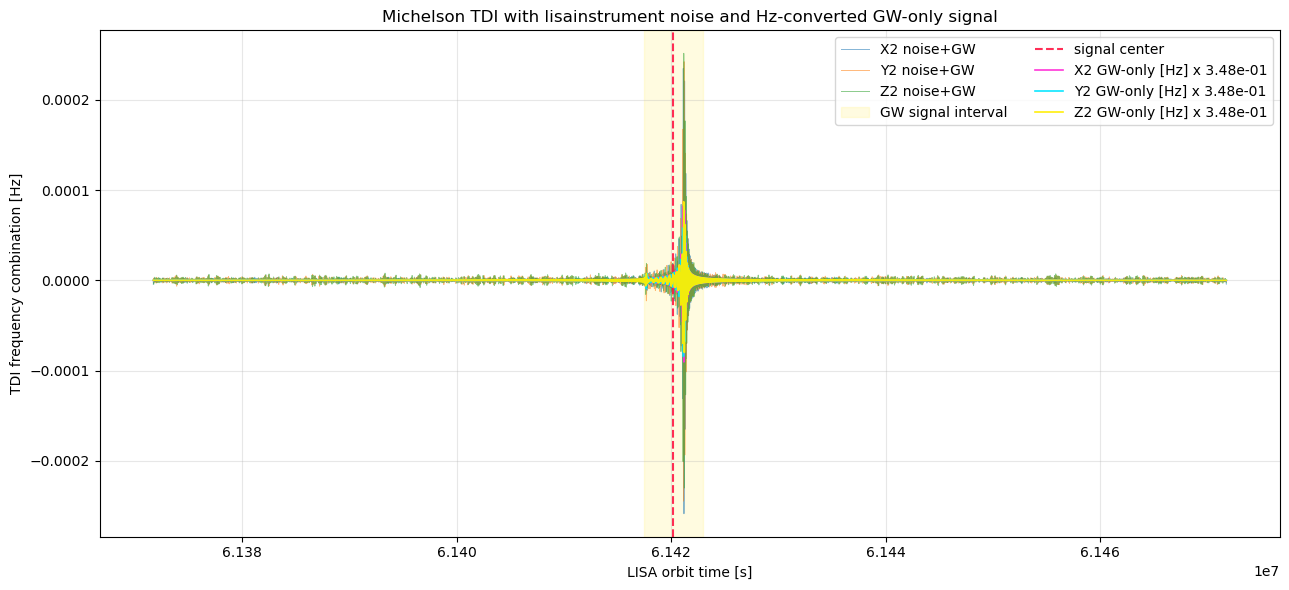

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/06_tdi_noisy_with_gw_signal_XYZ.png
  signal window: [61417505.52766406, 61422926.527663976] LISA seconds
  signal center: 61420216.02766402 LISA seconds
  visual GW-only signal scale factor: 3.481770e-01


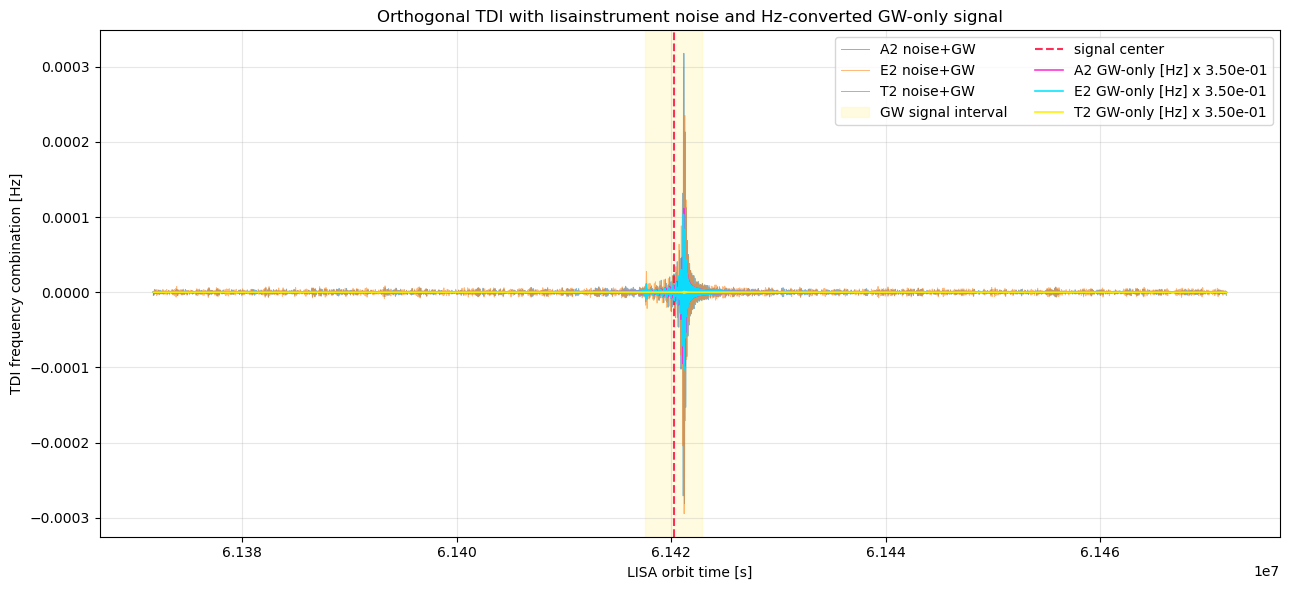

Saved plot: /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/plots/06_tdi_noisy_with_gw_signal_AET.png
  signal window: [61417600.12766406, 61422881.42766398] LISA seconds
  signal center: 61420240.77766402 LISA seconds
  visual GW-only signal scale factor: 3.499930e-01


In [34]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Overlay GW-only TDI signal on noisy lisainstrument TDI plots
# ============================================================

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TDI_NOISY_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
TDI_GW_ONLY_CSV = OUTPUT_DIR / "tdi_gw_only_XYZ_AET.csv"

PLOT_OVERLAY_XYZ = PLOT_DIR / "06_tdi_noisy_with_gw_signal_XYZ.png"
PLOT_OVERLAY_AET = PLOT_DIR / "06_tdi_noisy_with_gw_signal_AET.png"

SIGNAL_THRESHOLD_FRACTION = 1e-3
CENTRAL_FREQ_HZ = 2.816e14
SIGNAL_LINE_COLORS = {
    "X2": "#ff2bd6",
    "Y2": "#00e5ff",
    "Z2": "#ffee00",
    "A2": "#ff2bd6",
    "E2": "#00e5ff",
    "T2": "#ffee00",
}


def robust_absmax(arr):
    arr = np.asarray(arr, dtype=float)
    finite = np.isfinite(arr)
    if not np.any(finite):
        return 0.0
    return float(np.nanmax(np.abs(arr[finite])))


def find_signal_window(signal_arrays, t):
    power = np.zeros(len(t), dtype=float)
    for arr in signal_arrays:
        scale = robust_absmax(arr)
        if scale > 0.0:
            power += (np.asarray(arr, dtype=float) / scale) ** 2

    if not np.any(power > 0.0):
        return None

    threshold = SIGNAL_THRESHOLD_FRACTION * np.nanmax(power)
    idx = np.flatnonzero(power >= threshold)
    if len(idx) == 0:
        return None

    return float(t[idx[0]]), float(t[idx[-1]])


def overlay_scale(noisy_channels, signal_channels):
    noisy_max = max(robust_absmax(arr) for arr in noisy_channels.values())
    signal_max = max(robust_absmax(arr) for arr in signal_channels.values())
    if noisy_max == 0.0 or signal_max == 0.0:
        return 1.0
    return 0.35 * noisy_max / signal_max


def signal_column_hz(signal, base_name):
    hz_name = f"{base_name}_gw_hz"
    fractional_name = f"{base_name}_gw"
    if hz_name in signal.columns:
        return hz_name
    if fractional_name in signal.columns:
        signal[hz_name] = CENTRAL_FREQ_HZ * signal[fractional_name]
        print(f"Converted {fractional_name} to {hz_name} with central_freq={CENTRAL_FREQ_HZ:.6e} Hz")
        return hz_name
    raise KeyError(f"Expected {hz_name} or {fractional_name} in GW-only TDI CSV")


def plot_noisy_with_signal(noisy, signal, noisy_cols, signal_base_cols, title, outfile):
    t = noisy["t_lisa"].to_numpy()
    signal_t = signal["t_lisa"].to_numpy()

    if len(signal_t) != len(t) or not np.allclose(signal_t, t, rtol=0.0, atol=1e-6):
        signal = signal.set_index("t_lisa").reindex(t, method="nearest", tolerance=1e-6).reset_index()

    noisy_channels = {name: noisy[name].to_numpy() for name in noisy_cols}
    signal_channels = {
        name: signal[signal_column_hz(signal, src)].to_numpy()
        for name, src in zip(noisy_cols, signal_base_cols)
    }
    scale = overlay_scale(noisy_channels, signal_channels)
    window = find_signal_window(signal_channels.values(), t)

    plt.figure(figsize=(13, 6))

    for name, arr in noisy_channels.items():
        plt.plot(t, arr, lw=0.7, alpha=0.55, label=f"{name} noise+GW")

    if window is not None:
        plt.axvspan(window[0], window[1], color="#fff176", alpha=0.22, label="GW signal interval")
        plt.axvline(0.5 * (window[0] + window[1]), color="#ff1744", lw=1.5, ls="--", alpha=0.9, label="signal center")

    for name, arr in signal_channels.items():
        color = SIGNAL_LINE_COLORS.get(name, "#ff2bd6")
        plt.plot(
            t,
            scale * arr,
            lw=1.2,
            color=color,
            alpha=0.95,
            label=f"{name} GW-only [Hz] x {scale:.2e}",
        )

    plt.xlabel("LISA orbit time [s]")
    plt.ylabel("TDI frequency combination [Hz]")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(outfile, dpi=150)
    plt.show()

    if window is None:
        print(f"Saved plot: {outfile}")
        print("  signal window: not detected")
    else:
        print(f"Saved plot: {outfile}")
        print(f"  signal window: [{window[0]}, {window[1]}] LISA seconds")
        print(f"  signal center: {0.5 * (window[0] + window[1])} LISA seconds")
    print(f"  visual GW-only signal scale factor: {scale:.6e}")


noisy = pd.read_csv(TDI_NOISY_CSV)
signal = pd.read_csv(TDI_GW_ONLY_CSV)

plot_noisy_with_signal(
    noisy,
    signal,
    ["X2", "Y2", "Z2"],
    ["X2", "Y2", "Z2"],
    "Michelson TDI with lisainstrument noise and Hz-converted GW-only signal",
    PLOT_OVERLAY_XYZ,
)

plot_noisy_with_signal(
    noisy,
    signal,
    ["A2", "E2", "T2"],
    ["A2", "E2", "T2"],
    "Orthogonal TDI with lisainstrument noise and Hz-converted GW-only signal",
    PLOT_OVERLAY_AET,
)
